In [1]:
print("Hello World")


Hello World


In [2]:
import pandas as pd

In [3]:
from keras.datasets import mnist

I0000 00:00:1791457431.092532   35445 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791457431.570647   35445 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791457432.811515   35445 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [4]:
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

In [5]:
train_images.shape

(60000, 28, 28)

In [6]:
train_labels

array([5, 0, 4, ..., 5, 6, 8], shape=(60000,), dtype=uint8)

In [7]:
test_images.shape

(10000, 28, 28)

In [8]:
import keras
from keras import layers

model = keras.Sequential(
    [
        layers.Dense(512, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ]
)

In [9]:
model

<Sequential name=sequential, built=False>

In [10]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

E0000 00:00:1791457433.352623   35445 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [11]:
train_images = train_images.reshape((60000, 28 * 28))
train_images = train_images.astype("float32") / 255

test_images = test_images.reshape((10000, 28 * 28))
test_images = test_images.astype("float32") / 255

In [12]:
model.fit(train_images, train_labels, epochs=5, batch_size=128)

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9249 - loss: 0.2662
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9685 - loss: 0.1075
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9799 - loss: 0.0699
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9858 - loss: 0.0487
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9895 - loss: 0.0366


In [13]:
test_digits = test_images[0:10]

In [14]:
test_digits

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(10, 784), dtype=float32)

In [15]:
predictions = model.predict(test_digits)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


In [16]:
predictions[0]

array([9.1403543e-08, 1.3582938e-07, 8.3295654e-06, 6.5238717e-05,
       4.4655454e-10, 1.7868752e-08, 2.5705552e-11, 9.9992508e-01,
       2.3943494e-07, 8.0496545e-07], dtype=float32)

In [17]:
predictions[0].argmax()

np.int64(7)

In [18]:
predictions[0][7]

np.float32(0.9999251)

In [19]:
test_labels[0]

np.uint8(7)

In [20]:
test_labels[:15]

array([7, 2, 1, 0, 4, 1, 4, 9, 5, 9, 0, 6, 9, 0, 1], dtype=uint8)

In [21]:
test_loss, test_acc = model.evaluate(test_images, test_labels)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 775us/step - accuracy: 0.9798 - loss: 0.0654


In [32]:
import matplotlib.pyplot as plt

In [33]:
digit = train_images[4]

TypeError: Invalid shape (784,) for image data

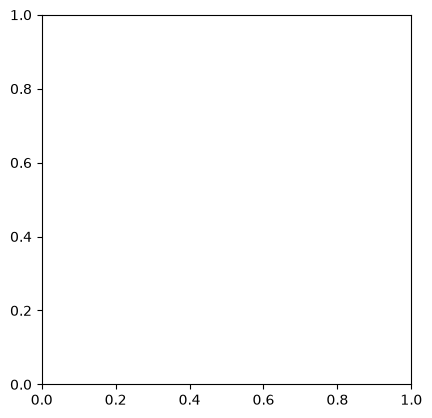

In [34]:
plt.imshow(digit, cmap=plt.cm.binary)
plt.show()